In [14]:
# Импорты и подключение к БД(Тип:Code)
import pandas as pd
import plotly.graph_objects as go
from sqlalchemy import create_engine

# Параметры подключения к нашей базе
DB_USER = 'analyst'
DB_PASSWORD = 'analyst123'
DB_HOST = 'localhost'
DB_PORT = '5432'
DB_NAME = 'crypto_analytics'

CONNECTION_STRING = f'postgresql+psycopg2://{DB_USER}:{DB_PASSWORD}@{DB_HOST}:{DB_PORT}/{DB_NAME}'
engine = create_engine(CONNECTION_STRING)

print('Подключение к базе успешно')

Подключение к базе успешно


In [15]:
# Загружаем данные из SQL
query = '''
select open_time, open, high, low, close, volume
from crypto_prices
where symbol = 'BTCUSDT'
order by open_time
'''

df = pd.read_sql(query, engine)

# Преобразуем дату
df['open_time'] = pd.to_datetime(df['open_time'])

# Посмотрим на первые 5 строк
df.head()

,open_time,open,high,low,close,volume
0,2024-10-13,63192.945312,63272.652344,62035.636719,62851.375000,1.817753e+10
1,2024-10-14,62848.398438,66482.492188,62442.152344,66046.125000,4.370696e+10
2,2024-10-15,66050.367188,67881.679688,64809.195312,67041.109375,4.886387e+10
3,2024-10-16,67042.460938,68375.289062,66758.726562,67612.718750,3.819519e+10
4,2024-10-17,67617.078125,67912.210938,66647.390625,67399.835938,3.279090e+10


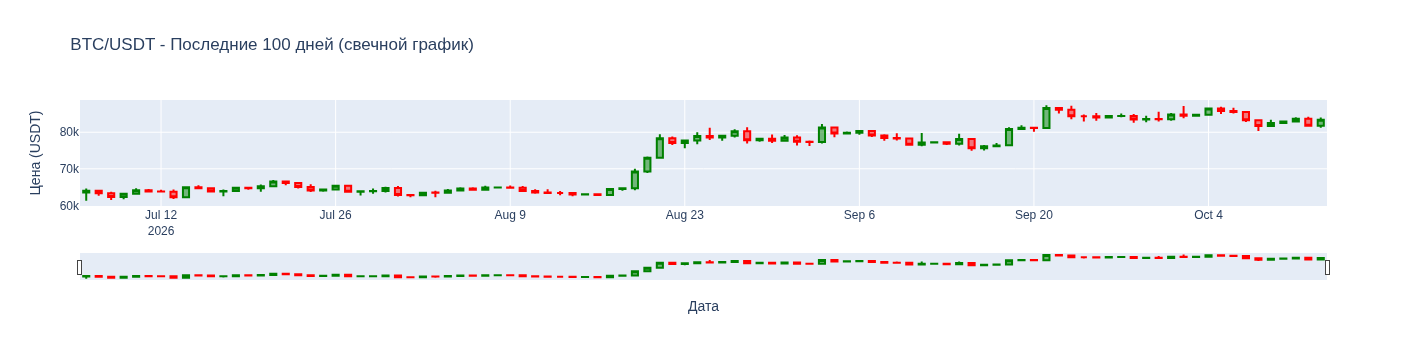

In [17]:
# Берем последние 100 дней, что бы график не был слишком тяжелым
df_plot = df.tail(100)

fig = go.Figure(data=[go.Candlestick(
    x=df_plot['open_time'],
    open=df_plot['open'],
    high=df_plot['high'],
    low=df_plot['low'],
    close=df_plot['close'],
    increasing_line_color='green',
    decreasing_line_color='red'
)])

fig.update_layout(
    title='BTC/USDT - Последние 100 дней (свечной график)',
    yaxis_title='Цена (USDT)',
    xaxis_title='Дата',
)

fig.show()